In [34]:
! pip install numpy 
! pip install pandas
! pip install matplotlib
! pip install seaborn
! pip install scikit-learn
! pip install nltk


In [35]:
import sqlite3 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import nltk 
import string 
import seaborn as sns 
import re 

import string 
from nltk.corpus import stopwords 
from nltk.stem import PorterStemmer 
from nltk.stem.wordnet import WordNetLemmatizer 
from nltk.stem.porter import PorterStemmer 
from tqdm import tqdm 
import os

In [36]:
import zipfile 
db_path = '/Users/vydhyamvishnusai/Downloads/AMAZON_FOOD_DATA_PROJECT/database.sqlite'
con = sqlite3.connect(db_path)
print("Database Connected!")

Database Connected!


In [37]:
filtered_data = pd.read_sql_query("""
SELECT * 
FROM REVIEWS 
WHERE Score != 3""", con)

def partition(x):
    if x < 3:
        return 'negative'
    return 'positive'



In [38]:
actual_score = filtered_data["Score"]
positivenegative = actual_score.map(partition)
filtered_data['Score'] = positivenegative

In [39]:
filtered_data.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,positive,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,negative,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,positive,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,negative,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,positive,1350777600,Great taffy,Great taffy at a great price. There was a wid...


# EDA

In [40]:
display = pd.read_sql_query("""
SELECT * FROM REVIEWS 
WHERE Score != 3 AND UserId = 'A395BORC6FGVXV'
ORDER BY ProductId""", con)
display

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,544173,B000U9WZ54,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
1,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
2,136304,B002Y7526Y,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...


In [41]:
sorted_data = filtered_data.sort_values('ProductId', axis = 0, ascending = True, inplace = False)
print(sorted_data)

            Id   ProductId          UserId                  ProfileName  \
138706  150524  0006641040   ACITT7DI6IDDL              shari zychinski   
138688  150506  0006641040  A2IW4PEEKO2R0U                        Tracy   
138689  150507  0006641040  A1S4A3IQ2MU7V4        sally sue "sally sue"   
138690  150508  0006641040     AZGXZ2UUK6X  Catherine Hallberg "(Kate)"   
138691  150509  0006641040  A3CMRKGE0P909G                       Teresa   
...        ...         ...             ...                          ...   
176791  191721  B009UOFTUI   AJVB004EB0MVK            D. Christofferson   
1362      1478  B009UOFU20   AJVB004EB0MVK            D. Christofferson   
303285  328482  B009UUS05I   ARL20DSHGVM1Y                        Jamie   
5259      5703  B009WSNWC4   AMP7K1O84DH1T                         ESTY   
302474  327601  B009WVB40S  A3ME78KVX31T21                         K'la   

        HelpfulnessNumerator  HelpfulnessDenominator     Score        Time  \
138706               

In [42]:
# remove duplicates 
final = sorted_data.drop_duplicates(subset = {"UserId", "ProfileName", "Time", "Summary", "Text"} ) 
final.shape 


(365333, 10)

In [43]:
# no of helpful words that a particlualar review has achived  
display = pd.read_sql_query("""
SELECT * FROM Reviews 
WHERE Score != 3 AND Id = 544173 or Id = 64422 
ORDER BY ProductId
""", con)
display

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,64422,B000MIDROQ,A161DK06JJMCYF,"J. E. Stephens ""Jeanne""",3,1,5,1224892800,Bought This for My Son at College,My son loves spaghetti so I didn't hesitate or...
1,544173,B000U9WZ54,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...


In [44]:
final = final[final.HelpfulnessNumerator <= final.HelpfulnessDenominator]
print(final.shape)

(365331, 10)


In [45]:
final['Score'].value_counts()

Score
positive    307967
negative     57364
Name: count, dtype: int64

In [46]:
final.duplicated().sum()

np.int64(0)

In [47]:
final.isna().sum()

Id                        0
ProductId                 0
UserId                    0
ProfileName               0
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   0
Text                      0
dtype: int64

In [48]:
final.info()

<class 'pandas.DataFrame'>
Index: 365331 entries, 138706 to 302474
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      365331 non-null  int64
 1   ProductId               365331 non-null  str  
 2   UserId                  365331 non-null  str  
 3   ProfileName             365331 non-null  str  
 4   HelpfulnessNumerator    365331 non-null  int64
 5   HelpfulnessDenominator  365331 non-null  int64
 6   Score                   365331 non-null  str  
 7   Time                    365331 non-null  int64
 8   Summary                 365331 non-null  str  
 9   Text                    365331 non-null  str  
dtypes: int64(4), str(6)
memory usage: 30.7 MB


In [49]:
final.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Time
count,365331.000000,365331.000000,365331.000000,3.653310e+05
mean,282791.663516,1.739220,2.188024,1.296127e+09
std,164586.489158,6.721836,7.347362,4.865088e+07
min,1.000000,0.000000,0.000000,9.393408e+08
25%,140723.500000,0.000000,0.000000,1.270858e+09
50%,278958.000000,0.000000,1.000000,1.311379e+09
75%,428530.500000,2.000000,2.000000,1.332893e+09
max,568454.000000,866.000000,878.000000,1.351210e+09


In [50]:
final.to_csv('./reviews_clean_file')

In [51]:
final = pd.read_csv('./reviews_clean_file', index_col=0)

In [52]:
final.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
138706,150524,0006641040,ACITT7DI6IDDL,shari zychinski,0,0,positive,939340800,EVERY book is educational,this witty little book makes my son laugh at l...
138688,150506,0006641040,A2IW4PEEKO2R0U,Tracy,1,1,positive,1194739200,"Love the book, miss the hard cover version","I grew up reading these Sendak books, and watc..."
138689,150507,0006641040,A1S4A3IQ2MU7V4,"sally sue ""sally sue""",1,1,positive,1191456000,chicken soup with rice months,This is a fun way for children to learn their ...
138690,150508,0006641040,AZGXZ2UUK6X,"Catherine Hallberg ""(Kate)""",1,1,positive,1076025600,a good swingy rhythm for reading aloud,This is a great little book to read aloud- it ...
138691,150509,0006641040,A3CMRKGE0P909G,Teresa,3,4,positive,1018396800,A great way to learn the months,This is a book of poetry about the months of t...


# 2. Text Preprocessing

In [53]:

sent_0 = final['Text'].values[0]
print(sent_0)
print("_"*50)

sent_1000 = final['Text'].values[125]
print(sent_1000)
print("_"*50)

sent_1500 = final['Text'].values[14810] #row number
print(sent_1500)
print("_"*50)

sent_4900 = final['Text'].values[14900]
print(sent_4900)
print("_"*50)

this witty little book makes my son laugh at loud. i recite it in the car as we're driving along and he always can sing the refrain. he's learned about whales, India, drooping roses:  i love all the new words this book  introduces and the silliness of it all.  this is a classic book i am  willing to bet my son will STILL be able to recite from memory when he is  in college
__________________________________________________
Though they might be a bit pricey for just the average dog owner like myself (as opposed to say someone in a profession working with dogs), they're great treats.<br />Perfect size for the quick little snack on the run.<br />And yeah... my dog loves these. At 13, she's getting pretty finicky, and these will gather her full attention.<br />Recommended.
__________________________________________________
Hey if my 18 year old cat will eat it, and I don't have to drive to Petsmart, then I'm a fan!<br /><br />Note: if your cat is a nibbler not a wolfer, give smaller portio

In [54]:
!pip install beautifulsoup4

In [57]:
# Remove all tags from an element using beautiful soup 
from bs4 import BeautifulSoup 
soup = BeautifulSoup(sent_0, "html.parser")
text = soup.get_text()
print(text)
print("="*50)

soup = BeautifulSoup(sent_1000, "html.parser")
text = soup.get_text()
print(text)
print("="*50)


soup = BeautifulSoup(sent_1500, "html.parser")
text = soup.get_text()
print(text)
print("="*50)



soup = BeautifulSoup(sent_4900, "html.parser")
text = soup.get_text()
print(text)
print("="*50)

this witty little book makes my son laugh at loud. i recite it in the car as we're driving along and he always can sing the refrain. he's learned about whales, India, drooping roses:  i love all the new words this book  introduces and the silliness of it all.  this is a classic book i am  willing to bet my son will STILL be able to recite from memory when he is  in college
Though they might be a bit pricey for just the average dog owner like myself (as opposed to say someone in a profession working with dogs), they're great treats.Perfect size for the quick little snack on the run.And yeah... my dog loves these. At 13, she's getting pretty finicky, and these will gather her full attention.Recommended.
Hey if my 18 year old cat will eat it, and I don't have to drive to Petsmart, then I'm a fan!Note: if your cat is a nibbler not a wolfer, give smaller portions several times a day. At first I was dumping out half a can and she would leave it and it dries out quickly. Then she wouldn't tou

In [58]:

def deconstructed(phrase):
    phrase = re.sub(r"won't", "will not", phrase)
    phrase = re.sub(r"can\'t", "can not", phrase)
    phrase = re.sub(r"n\'t", " not", phrase)
    phrase = re.sub(r"\'re", " are", phrase)
    phrase = re.sub(r"\'s", " is", phrase)
    phrase = re.sub(r"\'d", " would", phrase)
    phrase = re.sub(r"\'ll", " will", phrase)
    phrase = re.sub(r"\'t", " not", phrase)
    phrase = re.sub(r"\'ve", " have", phrase)
    phrase = re.sub(r"\'m", " am", phrase)
    return phrase


In [59]:
sent_4900 = deconstructed(sent_4900)
print(sent_4900)

I have been purchasing Cosmic catnip and scratching pads for as long as I have been a cat owner, and I have never been disappointed.  When I saw the cute, colorful packaging and the variety of flavors available for these treats, I could not resist.<br /><br />Sadly, my cats will not even acknowledge these as food.  They will not even smell them, let alone taste them.  Maybe I just got a bad batch, but my cats will usually eat anything that is offered to them at least once.  Even one of my dogs, who does anything to sneak a bite of the kitty food, was not too eager to eat one of these Philly Cheesesteak treats.<br /><br />The treats arrived somewhat hard, but it is obvious that they are the type that should be soft.  I do not know if this was Amazon is error for selling a stale product, or if the cold weather had something to do with it (it is getting down to the 20 is at night where I live).<br /><br />For nearly the same price as these treats, buy your kitties a tub of Cosmic catnip..

In [60]:

stopwords = set([
    "br", "a", "about", "above", "across", "after", "afterwards", "again", "against", 
    "ain", "all", "almost", "alone", "along", "already", "also", "although", 
    "always", "am", "among", "amongst", "amoungst", "amount", "an", "and", 
    "another", "any", "anyhow", "anyone", "anything", "anyway", "anywhere", 
    "are", "aren", "aren't", "around", "as", "at", "back", "be", "became", 
    "because", "become", "becomes", "becoming", "been", "before", "beforehand", 
    "behind", "being", "below", "beside", "besides", "between", "beyond", 
    "bill", "both", "bottom", "but", "by", "call", "can", "cannot", "cant", 
    "co", "con", "could", "couldn", "couldn't", "couldnt", "cry", "d", "de", 
    "describe", "detail", "did", "didn", "didn't", "do", "does", "doesn", 
    "doesn't", "doing", "don", "don't", "done", "down", "due", "during", 
    "each", "eg", "eight", "either", "eleven", "else", "elsewhere", "empty", 
    "enough", "etc", "even", "ever", "every", "everyone", "everything", 
    "everywhere", "except", "few", "fifteen", "fify", "fill", "find", "fire", 
    "first", "five", "for", "former", "formerly", "forty", "found", "four", 
    "from", "front", "full", "further", "get", "give", "go", "had", "hadn", 
    "hadn't", "has", "hasn", "hasn't", "hasnt", "have", "haven", "haven't", 
    "having", "he", "he'd", "he'll", "he's", "hence", "her", "here", 
    "hereafter", "hereby", "herein", "hereupon", "hers", "herself", "him", 
    "himself", "his", "how", "however", "hundred", "i", "i'd", "i'll", "i'm", 
    "i've", "ie", "if", "in", "inc", "indeed", "interest", "into", "is", 
    "isn", "isn't", "it", "it'd", "it'll", "it's", "its", "itself", "just", 
    "keep", "last", "latter", "latterly", "least", "less", "let's", "ll", 
    "ltd", "m", "ma", "made", "many", "may", "me", "meanwhile", "might", 
    "mightn", "mightn't", "mill", "mine", "more", "moreover", "most", "mostly", 
    "move", "much", "must", "mustn", "mustn't", "my", "myself", "name", 
    "namely", "neither", "never", "nevertheless", "next", "nine", "no", 
    "nobody", "none", "noone", "nor", "not", "nothing", "now", "nowhere", "o", 
    "of", "off", "often", "on", "once", "one", "only", "onto", "or", "other", 
    "others", "otherwise", "our", "ours", "ourselves", "out", "over", "own", 
    "part", "per", "perhaps", "please", "put", "rather", "re", "s", "same", 
    "see", "seem", "seemed", "seeming", "seems", "serious", "several", "shan", 
    "shan't", "she", "she'd", "she'll", "she's", "should", "should've", 
    "shouldn", "shouldn't", "show", "side", "since", "sincere", "six", 
    "sixty", "so", "some", "somehow", "someone", "something", "sometime", 
    "sometimes", "somewhere", "still", "such", "system", "t", "take", "ten", 
    "than", "that", "that'll", "that's", "the", "their", "theirs", "them", 
    "themselves", "then", "thence", "there", "there's", "thereafter", 
    "thereby", "therefore", "therein", "thereupon", "these", "they", "they'd", 
    "they'll", "they're", "they've", "thick", "thin", "third", "this", "those", 
    "though", "three", "through", "throughout", "thru", "thus", "to", 
    "together", "too", "top", "toward", "towards", "twelve", "twenty", "two", 
    "un", "under", "until", "up", "upon", "us", "ve", "very", "via", "was", 
    "wasn", "wasn't", "we", "we'd", "we'll", "we're", "we've", "well", "were", 
    "weren", "weren't", "what", "what's", "whatever", "when", "when's", 
    "whence", "whenever", "where", "where's", "whereafter", "whereas", 
    "whereby", "wherein", "whereupon", "wherever", "whether", "which", "while", 
    "whither", "who", "who's", "whoever", "whole", "whom", "whose", "why", 
    "why's", "will", "with", "within", "without", "won", "won't", "would", 
    "wouldn", "wouldn't", "y", "yet", "you", "you'd", "you'll", "you're", 
    "you've", "your", "yours", "yourself", "yourselves"
])

In [61]:
from tqdm import tqdm 
preprocessed_reviews = []
for sentence in tqdm(final['Text'].values):
    sentence = re.sub(r'http\S+', "", sentence)
    sentence = BeautifulSoup(sentence, "html.parser").get_text()
    sentence = deconstructed(sentence)
    sentence = re.sub("\S*\d\S*", "", sentence).strip()
    sentence = re.sub('[^A-Za-z]+', ' ', sentence)
    sentence =  ' '.join(e.lower() for e in sentence.split() if e not in stopwords)
    preprocessed_reviews.append(sentence.strip())
    

<>:7: SyntaxWarning: invalid escape sequence '\S'
<>:7: SyntaxWarning: invalid escape sequence '\S'
/var/folders/lh/9dhrv8n940scv062lp6f5q980000gn/T/ipykernel_4630/574117903.py:7: SyntaxWarning: invalid escape sequence '\S'
  sentence = re.sub("\S*\d\S*", "", sentence).strip()
 84%|████████▎ | 305823/365331 [00:18<00:03, 17383.21it/s]/var/folders/lh/9dhrv8n940scv062lp6f5q980000gn/T/ipykernel_4630/574117903.py:5: MarkupResemblesLocatorWarning: The input passed in on this line looks more like a filename than HTML or XML.

If you meant to use Beautiful Soup to parse the contents of a file on disk, then something has gone wrong. You should open the file first, using code like this:

    filehandle = open(your filename)

You can then feed the open filehandle into Beautiful Soup instead of using the filename.

However, if you want to parse some data that happens to look like a filename, then nothing has gone wrong: you are using Beautiful Soup correctly, and this warning is spurious and can 

In [62]:
#saving preprocessed text 
final['CleanedText'] = preprocessed_reviews 
local_filename = 'preprocessed_reviews.csv'
final.to_csv(local_filename, index=False)

In [63]:
# verifying from loading a few rows 
from IPython.display import display 
df_check = pd.read_csv('preprocessed_reviews.csv')
display(df_check.head(10))

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,CleanedText
0,150524,0006641040,ACITT7DI6IDDL,shari zychinski,0,0,positive,939340800,EVERY book is educational,this witty little book makes my son laugh at l...,witty little book makes son laugh loud recite ...
1,150506,0006641040,A2IW4PEEKO2R0U,Tracy,1,1,positive,1194739200,"Love the book, miss the hard cover version","I grew up reading these Sendak books, and watc...",i grew reading sendak books watching really ro...
2,150507,0006641040,A1S4A3IQ2MU7V4,"sally sue ""sally sue""",1,1,positive,1191456000,chicken soup with rice months,This is a fun way for children to learn their ...,this fun way children learn months year we lea...
3,150508,0006641040,AZGXZ2UUK6X,"Catherine Hallberg ""(Kate)""",1,1,positive,1076025600,a good swingy rhythm for reading aloud,This is a great little book to read aloud- it ...,this great little book read aloud nice rhythm ...
4,150509,0006641040,A3CMRKGE0P909G,Teresa,3,4,positive,1018396800,A great way to learn the months,This is a book of poetry about the months of t...,this book poetry months year it goes month cut...
5,150511,0006641040,A1C9K534BCI9GO,Laura Purdie Salas,0,0,positive,1344211200,Charming and childlike,"A charming, rhyming book that describes the ci...",a charming rhyming book describes circumstance...
6,150512,0006641040,A1DJXZA5V5FFVA,A. Conway,0,0,positive,1338249600,Must have.,I set aside at least an hour each day to read ...,i set aside hour day read son at point i consi...
7,150513,0006641040,ASH0DZQQF6AIZ,tessarat,0,0,positive,1325721600,A classic,I remembered this book from my childhood and g...,i remembered book childhood got kids it good i...
8,150514,0006641040,A2ONB6ZA292PA,Rosalind Matzner,0,0,positive,1313884800,Chicken soup with Rice,It's a great book with adorable illustrations....,it great book adorable illustrations a true cl...
9,150515,0006641040,A2RTT81R6Y3R7X,Lindylu,0,0,positive,1303171200,One of our family's favorite books,This book is a family favorite and was read to...,this book family favorite read children small ...


# Feature Extraction

In [65]:
from sklearn.feature_extraction.text import CountVectorizer , TfidfVectorizer 



In [66]:
df = pd.read_csv('preprocessed_reviews.csv')

In [ ]:
df

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,CleanedText
0,150524,0006641040,ACITT7DI6IDDL,shari zychinski,0,0,positive,939340800,EVERY book is educational,this witty little book makes my son laugh at l...,witty little book makes son laugh loud recite ...
1,150506,0006641040,A2IW4PEEKO2R0U,Tracy,1,1,positive,1194739200,"Love the book, miss the hard cover version","I grew up reading these Sendak books, and watc...",i grew reading sendak books watching really ro...
2,150507,0006641040,A1S4A3IQ2MU7V4,"sally sue ""sally sue""",1,1,positive,1191456000,chicken soup with rice months,This is a fun way for children to learn their ...,this fun way children learn months year we lea...
3,150508,0006641040,AZGXZ2UUK6X,"Catherine Hallberg ""(Kate)""",1,1,positive,1076025600,a good swingy rhythm for reading aloud,This is a great little book to read aloud- it ...,this great little book read aloud nice rhythm ...
4,150509,0006641040,A3CMRKGE0P909G,Teresa,3,4,positive,1018396800,A great way to learn the months,This is a book of poetry about the months of t...,this book poetry months year it goes month cut...
...,...,...,...,...,...,...,...,...,...,...,...
365326,193174,B009RSR8HO,A4P6AN2L435PV,romarc,0,0,positive,1350432000,LOVE!! LOVE!!,"LOVE, LOVE this sweetener!! I use it in all m...",love love sweetener i use baking unsweetened f...
365327,188389,B009SF0TN6,A1L0GWGRK4BYPT,Bety Robinson,0,0,positive,1350518400,Amazing!! Great sauce for everything!,You have to try this sauce to believe it! It s...,you try sauce believe it starts little sweet h...
365328,221795,B009SR4OQ2,A32A6X5KCP7ARG,sicamar,1,1,positive,1350604800,Awesome Taste,I bought this Hazelnut Paste (Nocciola Spread)...,i bought hazelnut paste nocciola spread local ...
365329,5703,B009WSNWC4,AMP7K1O84DH1T,ESTY,0,0,positive,1351209600,DELICIOUS,Purchased this product at a local store in NY ...,purchased product local store ny kids love its...


In [68]:
preprocessed_reviews = [
    '' if pd.isna(text) else str(text)
    for text in df['CleanedText']
] 
count_vect = CountVectorizer(max_features = 50000)
count_vect.fit(preprocessed_reviews)
final_counts = count_vect.transform(preprocessed_reviews)
print("The type of count vectorizer output:", type(final_counts))
print("The shape of out text BOW vectorizer:", final_counts.shape)
print("The number of unique words", final_counts.shape[1]) 

The type of count vectorizer output: <class 'scipy.sparse._csr.csr_matrix'>
The shape of out text BOW vectorizer: (365331, 50000)
The number of unique words 50000


In [69]:
features = count_vect.get_feature_names_out()
np.random.shuffle(features) 
print("some random features", features[:10])

some random features ['globe' 'dahls' 'hopefuly' 'commentors' 'premiun' 'retrofit' 'retreiver'
 'scotty' 'underweight' 'yearned']


In [70]:
word_freq = np.array(final_counts.sum(axis = 0)).flatten() 
top_cols = word_freq.argsort()[-10:]

In [71]:
print(top_cols) 

[ 8638 15913 34240 44590 43850 18284 17920 22234 44379 24800]


In [72]:
sample = final_counts[:5][:, top_cols].toarray()
pd.DataFrame(sample, columns = count_vect.get_feature_names_out()[top_cols])


,coffee,flavor,product,this,taste,great,good,it,the,like
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,1
3,0,0,0,1,0,1,1,1,1,2
4,0,0,0,1,0,0,0,1,2,0


# N-GRAMS

In [73]:
preprocessed_reviews = [
    '' if pd.isna(text) else str(text)
    for text in df['CleanedText']
] 
ngram_vectorizer = CountVectorizer(ngram_range = (1,2), min_df = 10, max_features = 5000)
ngram_vectorizer.fit(preprocessed_reviews)
print("Some n-gram features names:", ngram_vectorizer.get_feature_names_out()[:15]) 
print("="*70)
final_ngram_counts = ngram_vectorizer.transform(preprocessed_reviews)
print("The N-gram vectorizer output type:", type(final_ngram_counts))
print("The shape of our text N-Gram vectorizer:", final_ngram_counts.shape)
print("The number of unique n-grams", final_ngram_counts.shape[1])

Some n-gram features names: ['ability' 'able' 'able buy' 'able eat' 'able order' 'about' 'absolute'
 'absolute favorite' 'absolutely' 'absolutely best' 'absolutely delicious'
 'absolutely love' 'absolutely loved' 'absolutely loves' 'absorb']
The N-gram vectorizer output type: <class 'scipy.sparse._csr.csr_matrix'>
The shape of our text N-Gram vectorizer: (365331, 5000)
The number of unique n-grams 5000


# TF-IDF

In [74]:
tfidf_vectorizer = TfidfVectorizer(max_features = 5000)
#fits vectorizer  
tfidf_vectorizer.fit(preprocessed_reviews) 
print("some Tf-IDF feature names:", tfidf_vectorizer.get_feature_names_out()[:15])
print("="*70) 
# Transform data 
final_tfidf = tfidf_vectorizer.transform(preprocessed_reviews)
print("The Tf-IDF vectorizer output type:", type(final_tfidf))
print("The shape of our text Tf-IDF vectorizer:", final_tfidf.shape)
print("The number of unique words", final_tfidf.shape[1])

some Tf-IDF feature names: ['ability' 'able' 'about' 'absolute' 'absolutely' 'absorb' 'absorbed'
 'acai' 'accept' 'acceptable' 'access' 'accident' 'accidentally'
 'according' 'account']
The Tf-IDF vectorizer output type: <class 'scipy.sparse._csr.csr_matrix'>
The shape of our text Tf-IDF vectorizer: (365331, 5000)
The number of unique words 5000


In [77]:
!pip install wordcloud

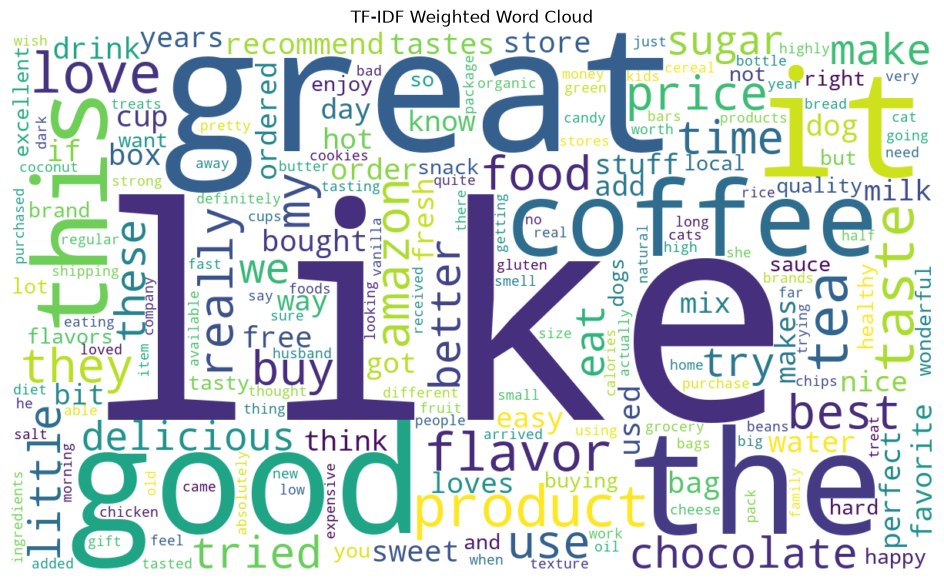

In [79]:
from wordcloud import WordCloud
tfidf_scores = np.array(final_tfidf.sum(axis = 0)).flatten()
feature_names = tfidf_vectorizer.get_feature_names_out()
#mapping word to scores 
word_scores = dict(zip(feature_names, tfidf_scores))
wc = WordCloud(width = 1200, height = 700, background_color = 'white')
wc.generate_from_frequencies(word_scores)
plt.figure(figsize = (12,7))
plt.imshow(wc, interpolation = "bilinear")
plt.axis('off')
plt.title("TF-IDF Weighted Word Cloud")
plt.show()

In [80]:
tfidf_bigram_vectorizer = TfidfVectorizer(ngram_range = (1,2), max_features = 8000)
#fits vectorizer  
tfidf_bigram_vectorizer.fit(preprocessed_reviews) 
print("some Tf-IDF feature names:", tfidf_bigram_vectorizer.get_feature_names_out()[:15])
print("="*70) 
# Transform data 
final_tfidf_bigram = tfidf_bigram_vectorizer.transform(preprocessed_reviews)
print("The Tf-IDF vectorizer output type:", type(final_tfidf_bigram))
print("The shape of our text Tf-IDF vectorizer:", final_tfidf_bigram.shape)

some Tf-IDF feature names: ['ability' 'able' 'able buy' 'able eat' 'able make' 'able order'
 'able purchase' 'able use' 'about' 'absolute' 'absolute best'
 'absolute favorite' 'absolutely' 'absolutely best' 'absolutely delicious']
The Tf-IDF vectorizer output type: <class 'scipy.sparse._csr.csr_matrix'>
The shape of our text Tf-IDF vectorizer: (365331, 8000)


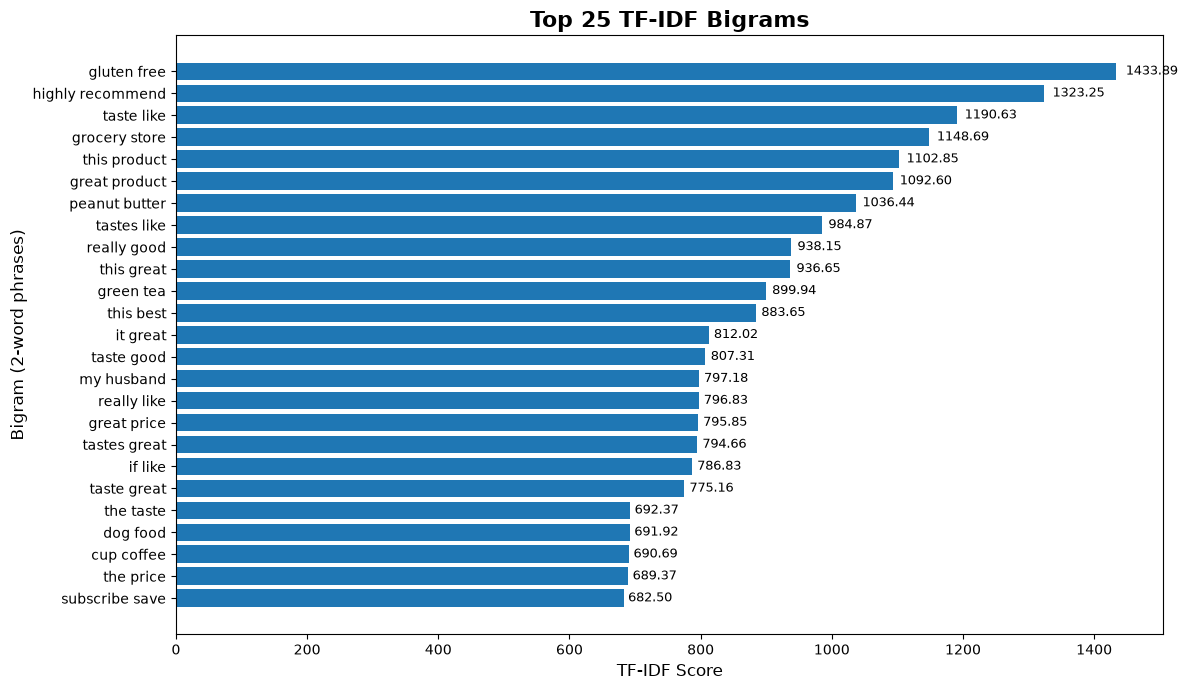

In [81]:
bigram_scores = np.asarray(final_tfidf_bigram.sum(axis = 0)).flatten()
bigram_features = tfidf_bigram_vectorizer.get_feature_names_out()
#Creating df 
bigram_df = pd.DataFrame({'ngram': bigram_features, 'score':bigram_scores})
#keep only bigrams 
bigram_df = bigram_df[bigram_df['ngram'].str.contains(r'^\w+\s\w+$')]
# sorting top 25 bigrams 
top_bigrams = bigram_df.sort_values(by = "score", ascending = False).head(25)
plt.figure(figsize = (12,7))
bars = plt.barh(top_bigrams['ngram'], top_bigrams['score']) 
plt.gca().invert_yaxis()
plt.title("Top 25 TF-IDF Bigrams", fontsize = 16, weight = 'bold' )
plt.xlabel("TF-IDF Score", fontsize = 12)
plt.ylabel("Bigram (2-word phrases)", fontsize = 12)
#Adding TF-IDF in bars 
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01 * width, bar.get_y() + bar.get_height()/2, f'{width:.2f}', va = 'center', fontsize = 9)
plt.tight_layout()
plt.show()

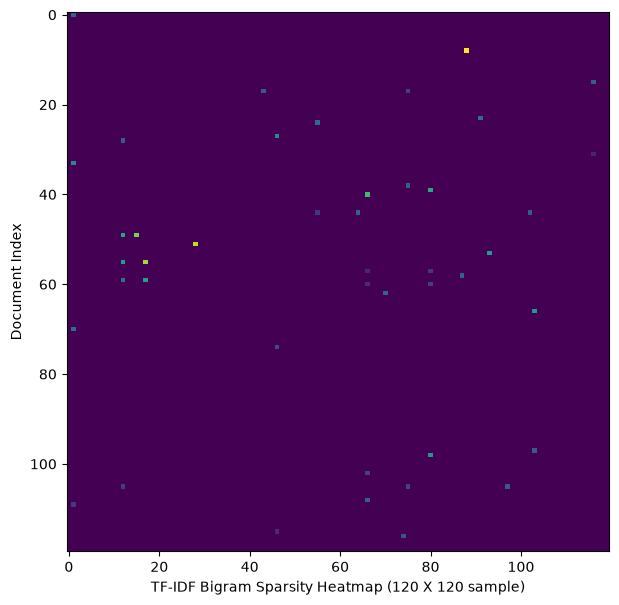

In [82]:
sample_bigram = final_tfidf_bigram[:120, :120].toarray()
plt.figure(figsize = (7,7))
plt.imshow(sample_bigram, aspect = 'auto')
plt.xlabel("TF-IDF Bigram Sparsity Heatmap (120 X 120 sample)") 
plt.ylabel("Document Index")
plt.show()

In [ ]:
# Now our objuective is to group similar customer reviews together to identify key themes and patterns in feedback 

In [84]:
! pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 12.3 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]2m1/2 [gensim]


In [87]:
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.metrics.pairwise import cosine_similarity 
from sklearn.decomposition import PCA 
from nltk.tokenize import word_tokenize 
import nltk 
nltk.download('punkt')
nltk.download('punkt_tab')




[nltk_data] Downloading package punkt to
[nltk_data]     /Users/vydhyamvishnusai/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/vydhyamvishnusai/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/vydhyamvishnusai/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [88]:
final = pd.read_csv('/Users/vydhyamvishnusai/Downloads/AMAZON_FOOD_DATA_PROJECT/preprocessed_reviews.csv')
final

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,CleanedText
0,150524,0006641040,ACITT7DI6IDDL,shari zychinski,0,0,positive,939340800,EVERY book is educational,this witty little book makes my son laugh at l...,witty little book makes son laugh loud recite ...
1,150506,0006641040,A2IW4PEEKO2R0U,Tracy,1,1,positive,1194739200,"Love the book, miss the hard cover version","I grew up reading these Sendak books, and watc...",i grew reading sendak books watching really ro...
2,150507,0006641040,A1S4A3IQ2MU7V4,"sally sue ""sally sue""",1,1,positive,1191456000,chicken soup with rice months,This is a fun way for children to learn their ...,this fun way children learn months year we lea...
3,150508,0006641040,AZGXZ2UUK6X,"Catherine Hallberg ""(Kate)""",1,1,positive,1076025600,a good swingy rhythm for reading aloud,This is a great little book to read aloud- it ...,this great little book read aloud nice rhythm ...
4,150509,0006641040,A3CMRKGE0P909G,Teresa,3,4,positive,1018396800,A great way to learn the months,This is a book of poetry about the months of t...,this book poetry months year it goes month cut...
...,...,...,...,...,...,...,...,...,...,...,...
365326,193174,B009RSR8HO,A4P6AN2L435PV,romarc,0,0,positive,1350432000,LOVE!! LOVE!!,"LOVE, LOVE this sweetener!! I use it in all m...",love love sweetener i use baking unsweetened f...
365327,188389,B009SF0TN6,A1L0GWGRK4BYPT,Bety Robinson,0,0,positive,1350518400,Amazing!! Great sauce for everything!,You have to try this sauce to believe it! It s...,you try sauce believe it starts little sweet h...
365328,221795,B009SR4OQ2,A32A6X5KCP7ARG,sicamar,1,1,positive,1350604800,Awesome Taste,I bought this Hazelnut Paste (Nocciola Spread)...,i bought hazelnut paste nocciola spread local ...
365329,5703,B009WSNWC4,AMP7K1O84DH1T,ESTY,0,0,positive,1351209600,DELICIOUS,Purchased this product at a local store in NY ...,purchased product local store ny kids love its...


In [ ]:
tokenized_reviews = [word_tokenize(text) for text in final['CleanedText'].dropna() if isinstance(text, str)] 


# Train the Word2Vec Model

In [92]:
from gensim.models import Word2Vec
sample_reviews = tokenized_reviews

In [93]:
w2v_model = Word2Vec(sentences = sample_reviews, vector_size = 50, window = 5, min_count = 3, workers = 4, sg = 1)


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

In [95]:
# Converting Each Review into a sentence vector 
def get_sentence_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv] 
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis = 0)
sample_reviews = tokenized_reviews 
review_vectors = np.array([get_sentence_vector(tokens, w2v_model) for tokens in sample_reviews])



In [96]:
print("Shape of the review vectors:", review_vectors.shape)

Shape of the review vectors: (364374, 50)


In [102]:
review_vectors

array([[ 0.00706168, -0.13717374,  0.17916992, ..., -0.07362127,
        -0.15110724,  0.07518783],
       [-0.12192898, -0.23148069,  0.15586655, ..., -0.14811675,
        -0.1303476 ,  0.15779942],
       [-0.02010099, -0.2567685 ,  0.19135895, ..., -0.0303858 ,
        -0.13608445,  0.04123335],
       ...,
       [-0.18096563, -0.31641927,  0.3079751 , ..., -0.42197955,
        -0.03662728,  0.09631275],
       [-0.11028937, -0.25702158,  0.17258558, ..., -0.19671056,
        -0.1094674 ,  0.15318878],
       [-0.11045392, -0.41968846,  0.28906995, ..., -0.11908507,
        -0.1830318 ,  0.07835108]], shape=(364374, 50), dtype=float32)

In [99]:
from sklearn.cluster import KMeans

In [103]:
num_clusters = 5 
kmeans_w2v = KMeans(n_clusters = num_clusters, random_state = 42)
clusters_w2v = kmeans_w2v.fit_predict(review_vectors)
non_null_cleaned_text_indices = final['CleanedText'].dropna().index 
cluster_series_aligned = pd.Series(clusters_w2v, index = non_null_cleaned_text_indices)
final['Cluster_Word2vec'] = cluster_series_aligned 
print("Cluster distribution")
print(final['Cluster_Word2vec'].value_counts()) 
final[['CleanedText', 'Cluster_Word2vec']].head(10)

Cluster distribution
Cluster_Word2vec
2.0    107325
1.0     92592
4.0     61366
0.0     58200
3.0     44891
Name: count, dtype: int64


,CleanedText,Cluster_Word2vec
0,witty little book makes son laugh loud recite ...,1.0
1,i grew reading sendak books watching really ro...,3.0
2,this fun way children learn months year we lea...,1.0
3,this great little book read aloud nice rhythm ...,2.0
4,this book poetry months year it goes month cut...,1.0
5,a charming rhyming book describes circumstance...,3.0
6,i set aside hour day read son at point i consi...,1.0
7,i remembered book childhood got kids it good i...,1.0
8,it great book adorable illustrations a true cl...,1.0
9,this book family favorite read children small ...,1.0


In [113]:
clusters_w2v

array([1, 3, 1, ..., 2, 4, 1], shape=(364374,), dtype=int32)

In [108]:
def get_similar_review(review_index, top_n = 5):
    sims = cosine_similarity(review_vectors[review_index].reshape(1,-1), review_vectors)[0]
    top_indices = sims.argsort()[-(top_n + 1): -1][::-1]
    print("Original Review:\n")
    print(final['Text'].iloc[review_index])
    print("\nSimilar Reviews:\n")
    for idx in top_indices:
        print(f"Similarity Score: {sims[idx]:.3f}") 
        print(final['Text'].iloc[idx])
        print("-"*80)

In [110]:
get_similar_review(8457, top_n = 5)

Original Review:

I have work for Nandos company back in UK for 4 years and I always loved the sauces they have and the garlic one is my flavourte, if you love spicies you got try these product.. :-)

Similar Reviews:

Similarity Score: 0.966
PG Tips is a wonderful tea. Lipton and Tetley tea have nothing on PG Tips.<br />I prefer this tea with a bit of cream and sugar. Wonderful tasting and a perfect afternoon (or anytime!) pick me up. I look forward to drinking it every day.
--------------------------------------------------------------------------------
Similarity Score: 0.963
Purchased a bag to give it a try, and  very disappointed.  Bulk Cheap coffee, that's roasted enough to dry the beans with little to no flavor.  I don't usually write reviews but had to let you know that this is not culinary treat.
--------------------------------------------------------------------------------
Similarity Score: 0.962
The temptation with a mallomar is to critique the one as three, the cookie and

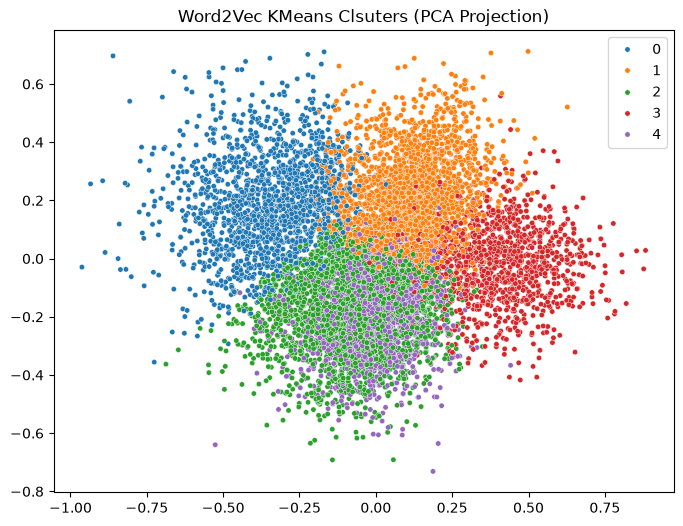

In [115]:
sample_size = 10000 
sample_idx = np.random.choice(len(review_vectors), sample_size , replace = False)
pca = PCA(n_components = 2, random_state = 42 )
w2v_pca = pca.fit_transform(review_vectors[sample_idx]) 

sample_clusters = clusters_w2v[sample_idx]
plt.figure(figsize = (8,6))
sns.scatterplot(
    x = w2v_pca[:,0],
    y = w2v_pca[:, 1],
    hue = sample_clusters,
    palette = 'tab10', 
    s = 15
)
plt.title("Word2Vec KMeans Clsuters (PCA Projection)")
plt.show()